# THP-1 + K562 + LPS: figures

Manuscript figures from the cell-state trajectories of `02_GetTrajectories.ipynb` (trajectory clusters on the OT-UMAP) and the single-lineage tradeSeq fits of `04_TradeSeqFits.K562.ipynb` and `04_TradeSeqFits.THP1.ipynb` (response-specificity volcano, fitted gene curves). Figures are saved to `EXP_DIR/figures/`.

Trajectory clusters `0` and `1` are the K562 states (strong and weak NF-kB response) and `2` is THP-1. In the gene-dynamics figures the K562 context is called `K562b` (as in gene clustering), to tell it apart from the K562 + TNF-alpha experiment. Time tags are 15 minutes apart (0-165 min).

In [1]:
import os
from pathlib import Path
import tempfile

import pandas as pd
import scanpy as sc

import chronopack as cp

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "thp1-k562-lps.hg38.rep"
TRADESEQ_DIRS = {
    "THP1": EXP_DIR / "intmd/sc-THP1_to_tradeSeq.fixed",
    "K562b": EXP_DIR / "intmd/sc-K562_to_tradeSeq.fixed",
}
FIG_DIR = EXP_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MINUTES_PER_TAG = 15
CONTEXT_COLORS = {"THP1": "#008000", "K562b": "#E35335"}

## Cell types and trajectory endpoints

The HVG object of `02_GetTrajectories.ipynb` (the original figure read `adata_both_prefiltered.h5ad`, which has the same cells, cell types and trajectory clusters). The OT-UMAP is rotated per cell type so that time runs upward within THP-1 and within K562, each cell type keeping its position (`groupby="cell_type"`).

In [2]:
adata = sc.read_h5ad(EXP_DIR / "output/adata_hvg.chk1.h5ad")
BASIS = cp.tl.rotate_embedding_to_time(adata, basis="ot_umap", groupby="cell_type", key_added="ot_umap_rot")
pd.crosstab(adata.obs["cell_type"], adata.obs["traj_clusters"])

traj_clusters,0,1,2
cell_type,,,
K562,1679,1449,0
THP1,0,0,787


Cells coloured by cell type and K562 trajectory cluster; the median positions of each cell type's first (0 min) and last (165 min) time tag are labelled.

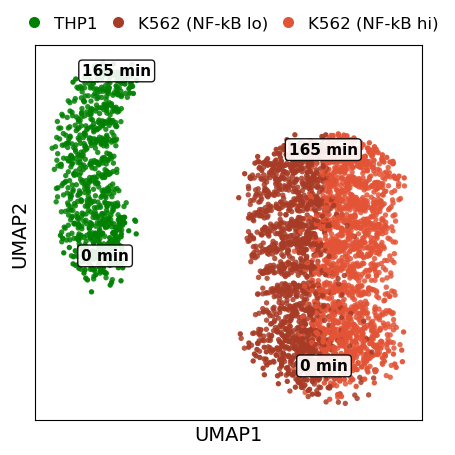

In [3]:
fig = cp.pl.cell_trajectories.trajectory_endpoints(
    adata,
    labels={"2": "THP1", "1": "K562 (NF-kB lo)", "0": "K562 (NF-kB hi)"},
    palette={"THP1": CONTEXT_COLORS["THP1"], "K562 (NF-kB lo)": "#A83B25", "K562 (NF-kB hi)": CONTEXT_COLORS["K562b"]},
    endpoint_key="cell_type",
    minutes_per_tag=MINUTES_PER_TAG,
    embedding_basis=BASIS,
    point_size=15,
    output=FIG_DIR / "umap_cell_type_endpoint_darker_same_size.pdf",
)

## Response specificity: K562b versus THP-1

The single-lineage association tests of the two 4-knot tradeSeq screens (`asso_df.1trajectory.nknots4.csv`), each with its genes' signed maximum log2 fold change against the start of the fitted curve (`sce_screen.1trajectory.nknots4.rds`, 100 points, pseudocount 0.1 as in the original `desc.pc_1e-1` descriptors).

In [4]:
asso = {}
for context, tradeseq_dir in TRADESEQ_DIRS.items():
    asso[context] = pd.read_csv(tradeseq_dir / "asso_df.1trajectory.nknots4.csv", index_col=0)
    asso[context]["signedMaxLog2FC_start"] = cp.tl.signed_max_log2fc_from_start(
        tradeseq_dir, asso[context].index, n_points=100, pseudocount=0.1
    )
{context: len(df) for context, df in asso.items()}

{'THP1': 10117, 'K562b': 11928}

Genes tested in either context are paired; a gene not tested in one context gets Wald 0, log2FC 0 and p-value 1 there. As in the original, `qval` is the smaller of the two p-values and only genes with `qval < 0.05` are plotted.

In [5]:
combined = cp.tl.combine_context_associations(
    asso["K562b"], asso["THP1"], qval_fun="min", keep_only_common=False, fill_missing=True
)
combined["qval"] = combined[["pvalue_1", "pvalue_2"]].min(axis=1)
combined = combined.query("qval < 0.05")
combined.head()

,waldStat_1,waldStat_2,qval,log2FC_t1,log2FC_t2,pvalue_1,pvalue_2
gene,,,,,,,
NFKBIA,2003.699526,706.560168,0.0,3.279622,3.513301,0.0,0.0
CXCL3,934.815330,457.629012,0.0,3.344712,5.015307,0.0,0.0
CD83,686.567863,128.338081,0.0,3.065487,2.227624,0.0,0.0
CD69,684.459444,0.000000,0.0,2.797295,0.000000,0.0,1.0
ICAM1,523.252528,246.064431,0.0,2.536403,2.718845,0.0,0.0


x: `|log2FC(K562b)| - |log2FC(THP1)|`; y: log10 of the larger Wald statistic, compressed below the 95th percentile of the Walds with `qval >= 0.01`. A gene is coloured as specific to a context when its |log2FC| is >= 1 there and <= 0.5 in the other. Labels: the top 10 genes by Wald and the 20 most specific genes of each context.

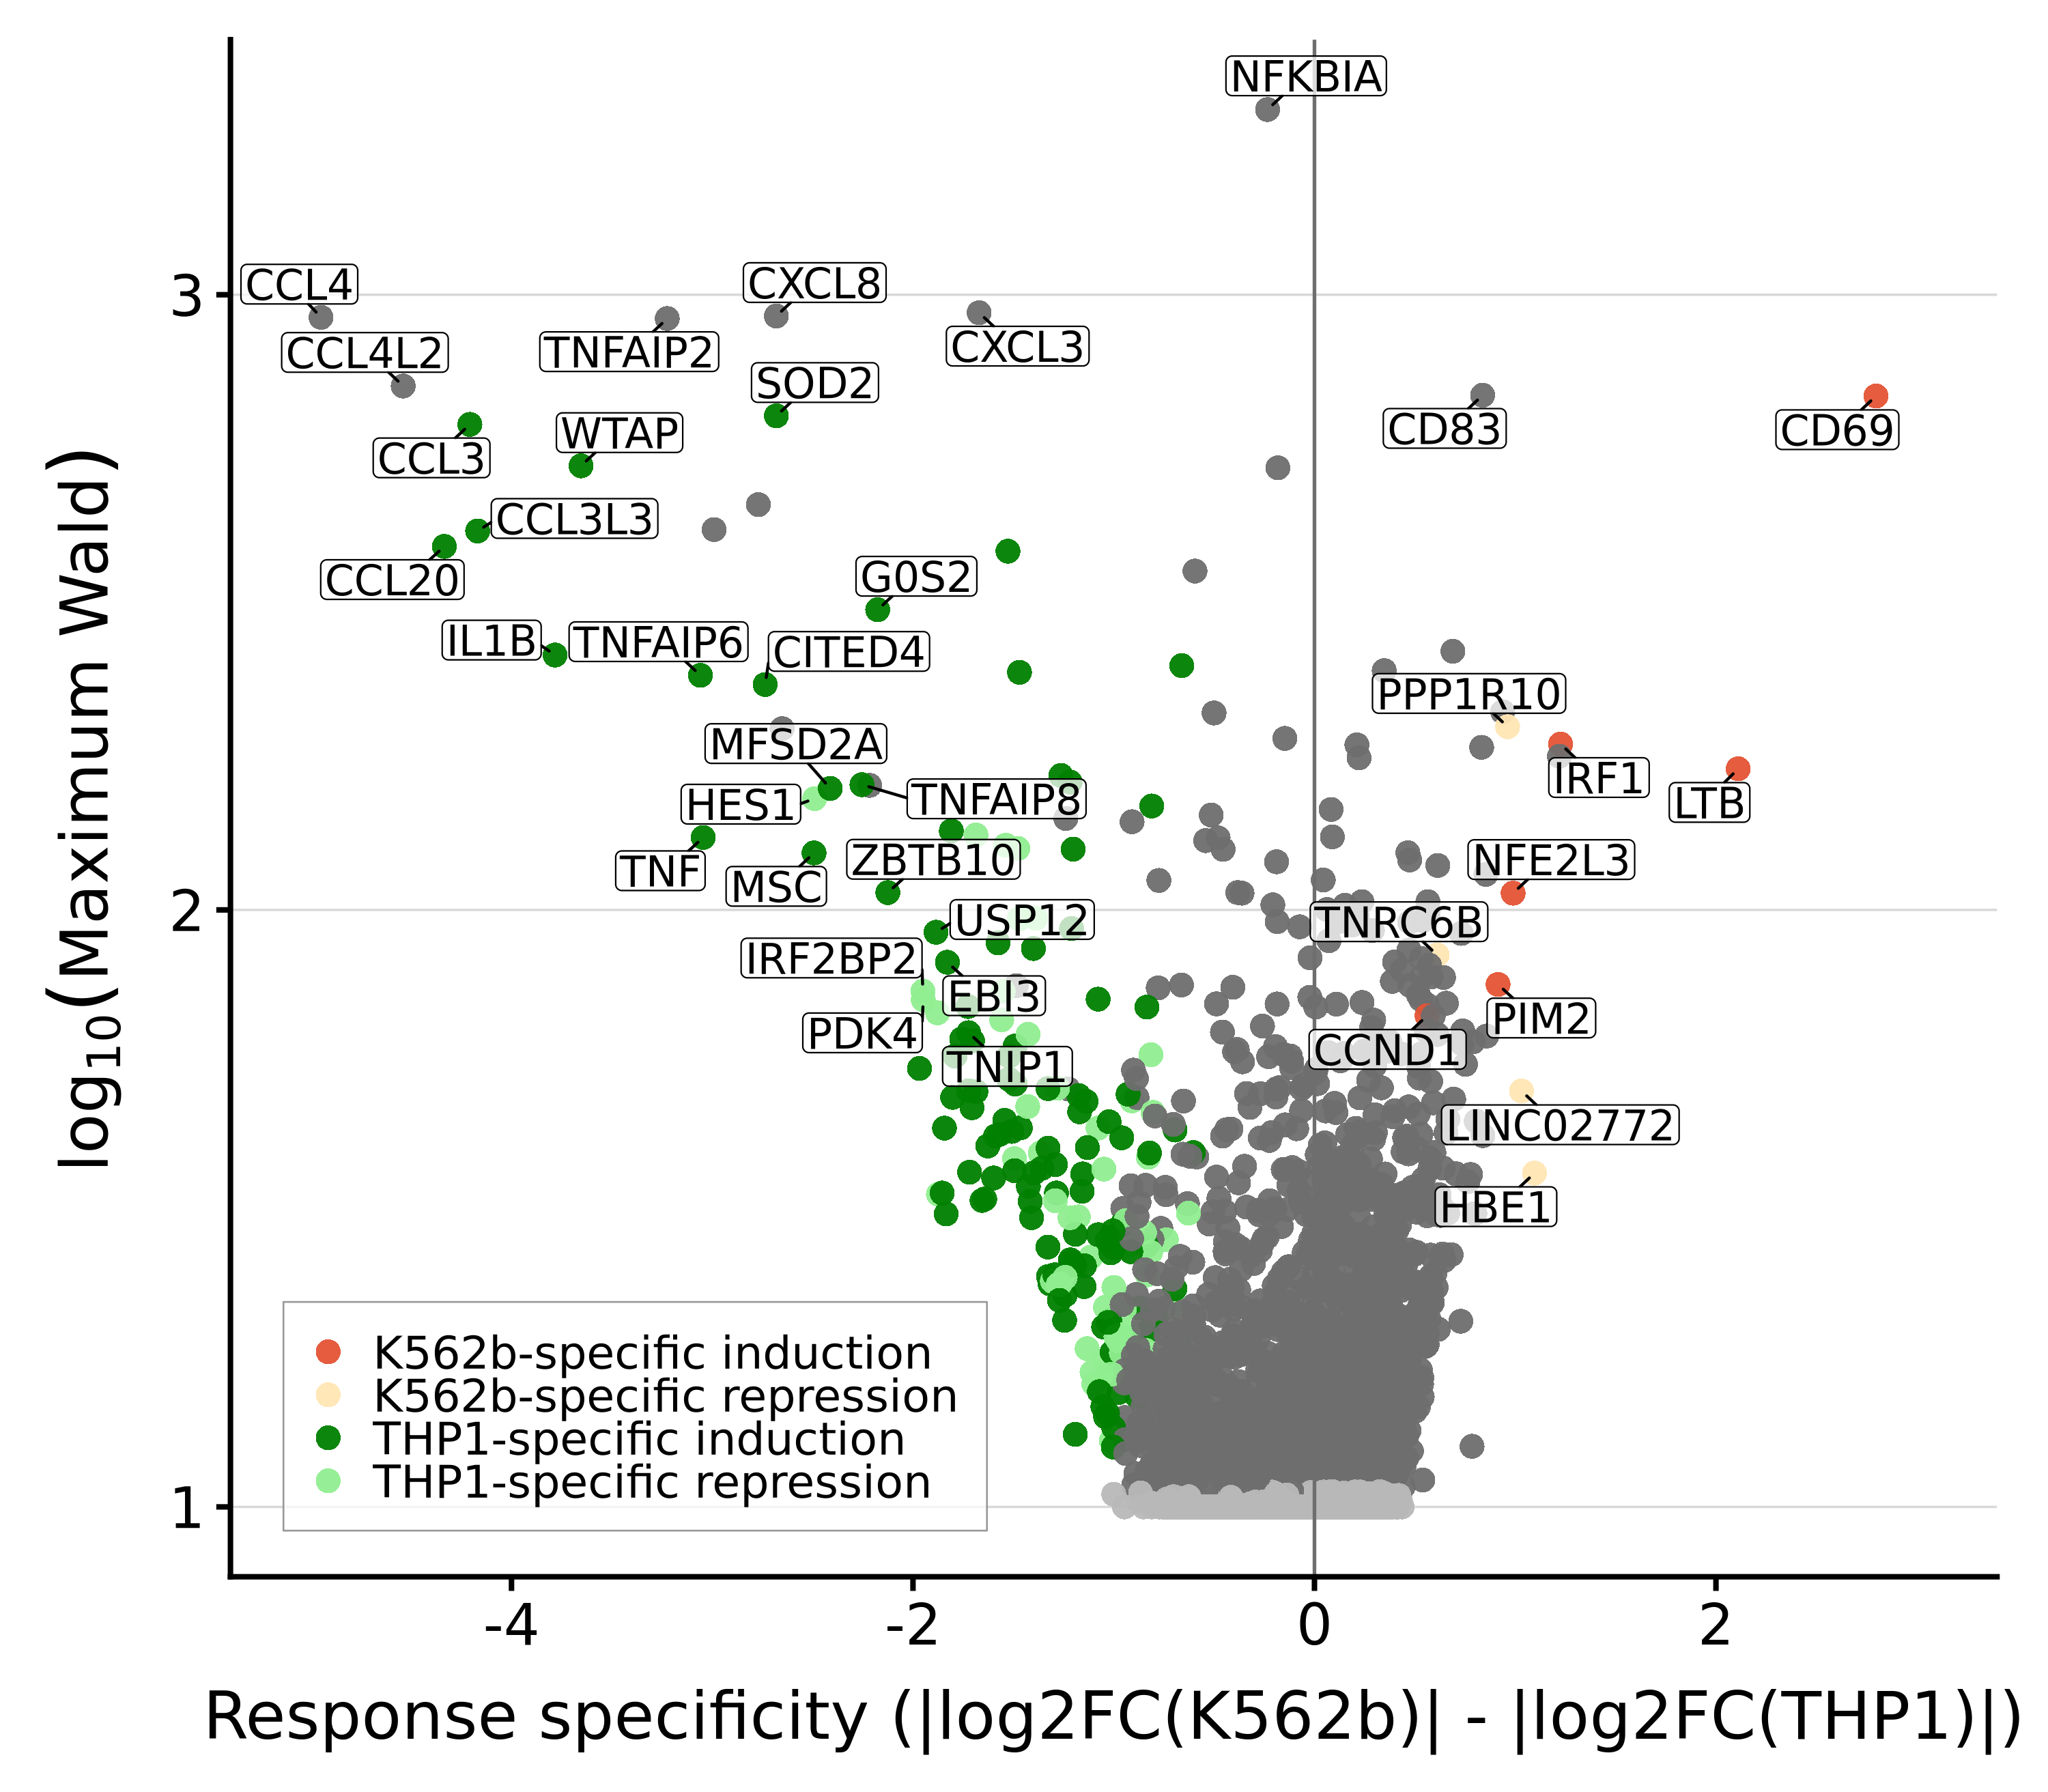

In [6]:
volcano = cp.pl.response_specificity_volcano(
    combined,
    ("K562b", "THP1"),
    require_fdr=False,
    fdr_thresh=0.01,
    dyn_thresh_condA=1,
    flat_thresh_condA=0.5,
    dyn_thresh_condB=1,
    flat_thresh_condB=0.5,
    x_lim=(-5, 3),
    y_lim=(10, 2000),
    label_top_wald=10,
    label_top_condA=20,
    label_top_condB=20,
    label_size=5.2,
    axis_title_size=23,
    axis_text_size=20,
    legend_text_size=16,
    point_size=3.5,
    legend_pos=(0.03, 0.03),
    legend_just=(0, 0),
    repel_force=1.4,
    repel_box_padding=0.25,
    repel_point_padding=0.10,
    repel_seed=7,
    output=FIG_DIR / "THP1vsK562_ResponseSpecificityVolcanoPlot.pdf",
)
volcano

In [7]:
volcano_genes = volcano.metadata["genes"]
display(volcano_genes["side"].value_counts())
volcano_genes.query("labelled")[["gene", "side"]].sort_values("side").groupby("side")["gene"].apply(", ".join)

side
sig_mid      1475
other        1080
condB_ind     127
condB_rep      66
condA_ind       6
condA_rep       4
Name: count, dtype: int64

side
condA_ind                 CD69, IRF1, LTB, NFE2L3, PIM2, CCND1
condA_rep                     PPP1R10, TNRC6B, LINC02772, HBE1
condB_ind    CCL3, MSC, MFSD2A, CITED4, IL1B, USP12, TNIP1,...
condB_rep                                  HES1, PDK4, IRF2BP2
sig_mid      CCL4, CCL4L2, TNFAIP2, CXCL8, CD83, CXCL3, NFKBIA
Name: gene, dtype: object

## Gene dynamics: THP-1 and K562b NB-GAM curves

Fitted curves (95% bands) of the 8-knot single-lineage fits, one per context. Genes with p < 0.05 in a context's 4-knot screen are in its full 8-knot refit (`sce.1trajectory.nknots8.rds`); the others are fitted here at 8 knots on the same inputs (`cp.tl.fit_gene_dynamics(genes=...)`, which equals their fit in the full refit). Points are cells (counts scaled to the reference library size of the curves, log1p) and white circles are the means per time point.

In [8]:
GENES = ["NFKBIA", "NFKBIZ", "CCL4", "TNF", "ICAM1", "BIRC3", "CD69", "IRF1"]

refit_genes = {c: set(pd.read_csv(d / "screen_genes.1trajectory.nknots4.csv")["gene"]) for c, d in TRADESEQ_DIRS.items()}
input_genes = {c: set(pd.read_csv(d / "subset_genes.csv")["gene"]) for c, d in TRADESEQ_DIRS.items()}
pd.DataFrame(
    {
        c: ["8-knot refit" if g in refit_genes[c] else "ad hoc fit" if g in input_genes[c] else "not a tradeSeq input"
            for g in GENES]
        for c in TRADESEQ_DIRS
    },
    index=GENES,
)

,THP1,K562b
NFKBIA,8-knot refit,8-knot refit
NFKBIZ,8-knot refit,8-knot refit
CCL4,8-knot refit,8-knot refit
TNF,8-knot refit,8-knot refit
ICAM1,8-knot refit,8-knot refit
BIRC3,8-knot refit,8-knot refit
CD69,not a tradeSeq input,8-knot refit
IRF1,ad hoc fit,8-knot refit


In THP-1, IRF1 (screen p ~ 1) and CD69 are not in the 8-knot refit; all eight genes are in the K562b refit. IRF1 is fitted ad hoc from the THP-1 tradeSeq inputs. CD69 has only 8 UMIs in the 787 THP-1 cells, so the low-count filter of `03_PrepareForTradeSeq.ipynb` removed it from the THP-1 inputs; it is fitted ad hoc from the THP-1 cells of `adata_full.chk1.h5ad`, written as tradeSeq inputs to a temporary folder (same cells, times and library-size offsets as the THP-1 fit).

In [9]:
curves, observations = [], []
for context, tradeseq_dir in TRADESEQ_DIRS.items():
    in_refit = [g for g in GENES if g in refit_genes[context]]
    curves.append(cp.tl.predict_gene_dynamics(
        tradeseq_dir, in_refit, sce_file="sce.1trajectory.nknots8.rds", time_max=165
    ).assign(context=context))
    ad_hoc = [g for g in GENES if g not in refit_genes[context] and g in input_genes[context]]
    if ad_hoc:
        fit = cp.tl.fit_gene_dynamics(input_dir=tradeseq_dir, genes=ad_hoc, final_nknots=8, verbose=False)
        curves.append(cp.tl.predict_gene_dynamics(fit, time_max=165).assign(context=context))
    observations.append(cp.tl.observed_gene_dynamics(
        tradeseq_dir, [g for g in GENES if g in input_genes[context]], time_max=165
    ).assign(context=context))

not_input = {c: [g for g in GENES if g not in input_genes[c]] for c in TRADESEQ_DIRS}
not_input

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In RNGkind("Mersenne-Twister", "Inversion", "Rounding") :  
R callback write-console: 
   
R callback write-console:  non-uniform 'Rounding' sampler used
  


{'THP1': ['CD69'], 'K562b': []}

In [10]:
adata_full = sc.read_h5ad(EXP_DIR / "output/adata_full.chk1.h5ad")
cell_types = {"THP1": "THP1", "K562b": "K562"}
for context, genes in not_input.items():
    if not genes:
        continue
    # The other panel genes are written alongside (tradeSeq needs more than one gene); only `genes` are fitted.
    cells = adata_full.obs["cell_type"] == cell_types[context]
    adata_ctx = adata_full[cells, GENES].copy()
    with tempfile.TemporaryDirectory() as input_dir:
        fit = cp.tl.fit_gene_dynamics(
            adata_ctx, input_dir=input_dir, prepare_inputs=True, genes=genes, final_nknots=8, verbose=False
        )
        curves.append(cp.tl.predict_gene_dynamics(fit, time_max=165).assign(context=context))
        observations.append(cp.tl.observed_gene_dynamics(fit, time_max=165).assign(context=context))
del adata_full
curves = pd.concat(curves, ignore_index=True)
observations = pd.concat(observations, ignore_index=True)
curves.groupby(["context", "gene"]).size().unstack(0)

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In RNGkind("Mersenne-Twister", "Inversion", "Rounding") :  
R callback write-console: 
   
R callback write-console:  non-uniform 'Rounding' sampler used
  


context,K562b,THP1
gene,,
BIRC3,100,100
CCL4,100,100
CD69,100,100
ICAM1,100,100
IRF1,100,100
NFKBIA,100,100
NFKBIZ,100,100
TNF,100,100


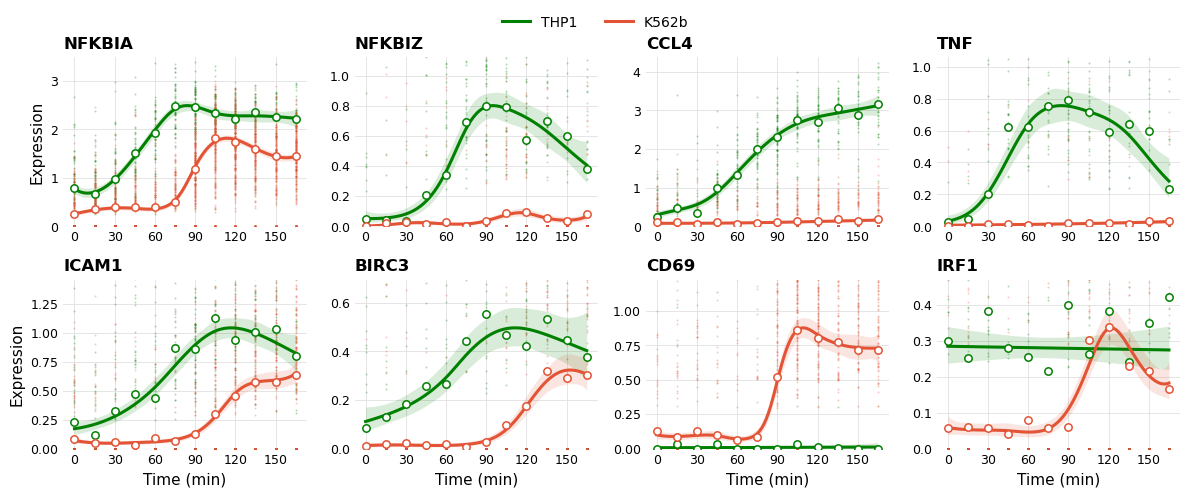

In [11]:
fig = cp.pl.gene_dynamics_curves(
    curves,
    GENES,
    observations=observations,
    group_col="context",
    ncols=4,
    colors=CONTEXT_COLORS,
    output=FIG_DIR / "thp1_k562b_gene_curves.pdf",
)